## Bode System ID Python Verification

In [12]:
import matplotlib.pyplot as plt
import numpy as np
#import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [13]:
import os, shutil

In [14]:
import random_bode_generator as rbg

In [15]:
plt.rcParams['font.size'] = 14

### Download CSV Files

Depending on how you use github, you may need to manually download the csv files from here:

[csv_files from class 18 github](https://github.com/kraussry/student_git_345_F26/tree/main/lecture_345/class_18_more_bode_sketching_and_start_of_bode_id/csv_files)

**Note:** The code below assumes you save the csv files to a folder called `csv_files` in the same folder where you saved this notebook.

## Example 1

In [23]:
ls csv_files/*.csv

csv_files/bode_id_001_11_04_2026_09_36AM.csv
csv_files/bode_id_002_11_04_2026_12_09PM.csv
csv_files/bode_id_003_11_04_2026_02_18PM.csv


### Define $G_1$ here

In [35]:
p = 5*2*pi
A = 0.1

$$G_1(s) = \frac{A \cdot p}{s(s+p)}$$

Pure int:

In [36]:
part1_1 = TF(1,[1,0])*A
part1_1

TransferFunction(
array([0.1]),
array([1, 0]),
outputs=1, inputs=1)

In [37]:
part2_1 = TF(p,[1,p])
part2_1

TransferFunction(
array([31.41592654]),
array([ 1.        , 31.41592654]),
outputs=1, inputs=1)

In [38]:
G1 = part1_1*part2_1
G1

TransferFunction(
array([3.14159265]),
array([ 1.        , 31.41592654,  0.        ]),
outputs=1, inputs=1)

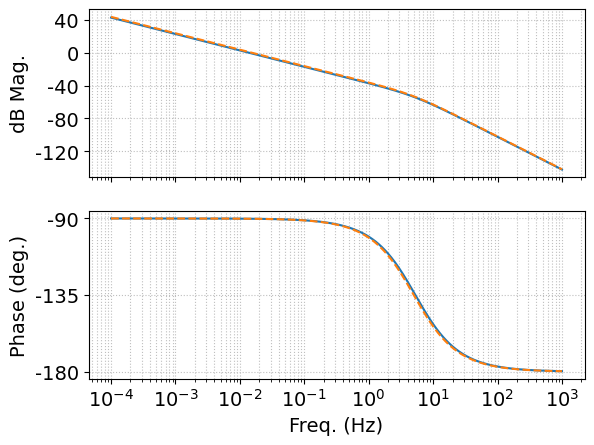

In [42]:
rbg.plot_bode_from_csv("csv_files/bode_id_001_11_04_2026_09_36AM.csv")
rbg.plot_bode_for_TF(G1, clear=False, plot_str='--')

## Example 2

In [43]:
ls csv_files/*.csv

csv_files/bode_id_001_11_04_2026_09_36AM.csv
csv_files/bode_id_002_11_04_2026_12_09PM.csv
csv_files/bode_id_003_11_04_2026_02_18PM.csv


In [45]:
w2 = 0.5*2*pi
z2 = 0.2
p2 = 12*2*pi

In [52]:
part1_2 = TF(w2**2,[1,2*z2*w2,w2**2])
part2_2 = TF(p2,[1,p2])
A = 0.07
G2 = part1_2*part2_2*A
G2

TransferFunction(
array([52.09054482]),
array([  1.        ,  76.65486075, 104.61780665, 744.15064033]),
outputs=1, inputs=1)

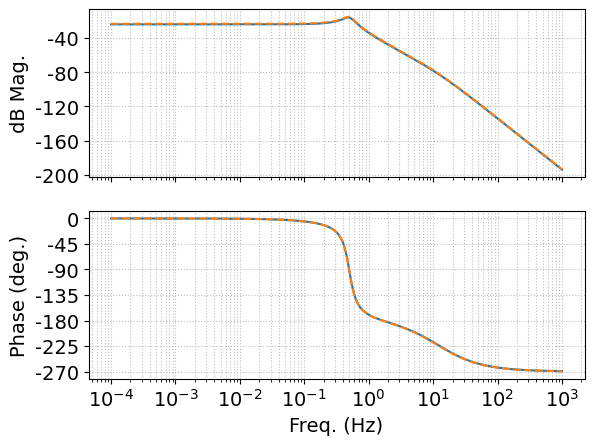

In [53]:
rbg.plot_bode_from_csv("csv_files/bode_id_002_11_04_2026_12_09PM.csv")
rbg.plot_bode_for_TF(G2, clear=False, plot_str='--')

## Example 3

$$G_3(s) = \frac{s \cdot \omega_n^2}{s^2 + 2\zeta \omega_n s + \omega_n^2}$$

In [75]:
w3 = 0.53*2*pi
z3 = 0.4
A = 0.09
G3 = TF([1,0],[1,2*z3*w3,w3**2])*A*w3**2
G3

TransferFunction(
array([0.99805388, 0.        ]),
array([ 1.        ,  2.66407057, 11.08948751]),
outputs=1, inputs=1)

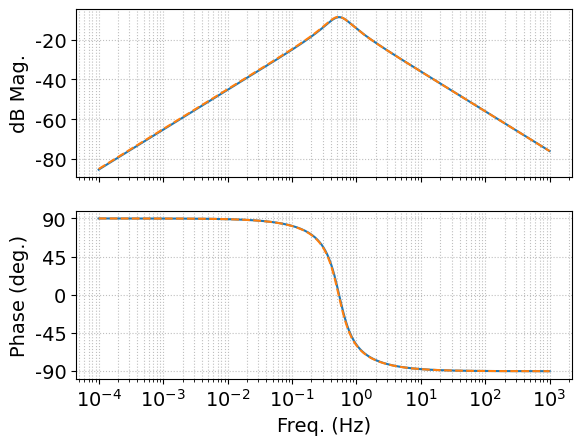

In [76]:
rbg.plot_bode_from_csv("csv_files/bode_id_003_11_04_2026_02_18PM.csv")
rbg.plot_bode_for_TF(G3, clear=False, plot_str='--')

## Random Example

Create a random TF, but don't look at its poles and zeros

In [78]:
G_R1 = rbg.random_Bode_TF()

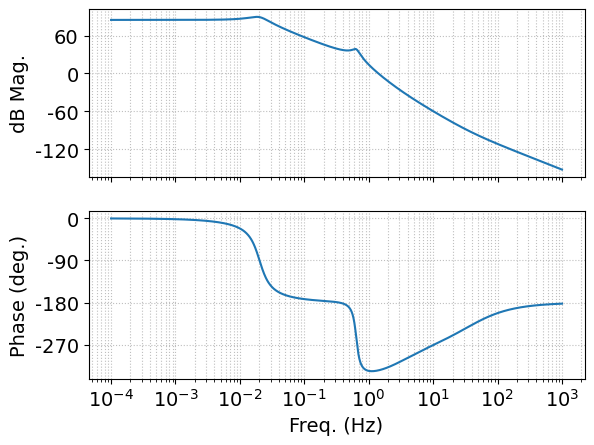

In [79]:
rbg.plot_bode_for_TF(G_R1)